# What malignancy means, and what a 3D surface can show

**Questions.** What does malignant mean? Which of its signs reach a lesion's 3D surface? Can Laplace–Beltrami (LB) descriptors be designed from those signs, instead of being tried and hoped for? And is spiculation just spikes on the tumour's boundary?

**How to rerun:** [`docs/reproductions/lb-malignancy.md`](../docs/reproductions/lb-malignancy.md). Code: `abus_classification/features/shape_descriptor/malignancy_signs.py` and `abus_classification/lb_malignancy.py`.

**Sections 1–8 use Train+Validation only (130 lesions, 75 malignant), on ground-truth masks unless they say otherwise. Section 9 is one second look at Test, from a plan frozen in advance.** Test had already been used once, in `lb-feature-evaluation.ipynb`.

**The short answer.** Tissue lines around the lesion replicated on Test; mask surface shape is modest and does not survive real segmentation. The three-number hybrid reached AUC 0.854 and ACC 0.814 on Test, but did not beat size + spiculation (0.889, 0.871), and its tilt term failed.

## 1. What malignancy means

Malignancy is a behaviour of cells, not a shape. A malignant tumour invades the tissue around it and can spread to distant sites; invasion and metastasis are among the hallmarks of cancer [1]. A benign tumour stays local. The answer comes from histology, on a biopsy.

Shape matters only because the way a tumour grows leaves a footprint:

- **Benign lesions tend to push.** The sonographic benign pattern is an ellipsoid or fewer than four gentle lobulations, with a thin echogenic pseudocapsule [2].
- **Malignant lesions tend to invade.** In one model of invasion, oxygen and nutrient gradients make the edge unstable, and cell adhesion is what keeps it well defined [3]. That is a mathematical hypothesis backed by simulations and culture experiments, not a clinical finding.
- **Invasion reorganises the tissue around the tumour.** In mouse mammary tumours, collagen wraps taut around non-invading regions, while cells invade along fibres that run out of the boundary [4]. In 196 patients with breast carcinoma, fibres perpendicular to the boundary predicted poor survival (hazard ratios 3.0–3.9) and stayed an independent indicator regardless of grade and size [5]. Those fibres are microscopic, far finer than ultrasound resolves at the 0.6 mm voxels used here.
- **Spicules are strands in that tissue.** In malignant lesions they come from tumour infiltration, a desmoplastic response or periductal fibrosis; in benign ones, from fibrous tissue, lipid-filled spaces or sclerotic stroma [6].

**Why shape cannot settle it.** Both directions fail. In mammographic-pathologic work, sclerosing adenosis, radial scars and postsurgical scars appear spiculated and are benign [6]. Triple-negative cancers often look benign: in one series 57% (43/75) had circumscribed margins on ultrasound [7], and a review reports benign features in 21–41% of them [8]. So shape can shift the probability; it cannot make the diagnosis.

## 2. From signs to geometry

| Clinical sign | Evidence | What it would be in 3D | Measured here by | Needs |
|---|---|---|---|---|
| Oval, circumscribed | Benign in 84% and 90% of such masses [9] | Area at low frequency, little bending | Spectral roundness, area budget, bending | Surface |
| Fewer than four gentle lobes | Part of the benign pattern [2] | A few wide peaks | Large lobes | Surface |
| Irregular shape | Malignant in 62% [9] | Area spent at high frequency | Area budget, bending | Surface |
| Microlobulated or angular margin | Independent predictors on automated ultrasound [10] | Many small peaks, sharp corners | Lobes, angularity | Surface |
| Not parallel to the skin | Malignant in 69% [9] | Long axis tilted to the skin | Depth share, tilt | Surface and beam |
| Spiculated margin | Malignant in 86%, on 22 masses [9] | Thin lines leaving the surface | Radial lines | Surface and image |
| Retraction in the coronal plane | Strongest independent predictor on automated ultrasound, OR 76.7 [10] | Tissue lines converging on the surface | Radial lines; Tan's spiculation | Surface and image |
| Cancers that look benign | [7, 8] | Nothing | Nothing: only histology | Biopsy |

On automated ultrasound, once retraction and microlobulated margins were in the model, shape, orientation, spiculated margin and size were no longer independent predictors [10]. So the signs overlap, and they cannot simply be added up.

Size is not a clinical sign in this list, yet it predicts class here (AUC 0.72). We do not know how much of that comes from which lesions reached this dataset, so it is kept apart as a baseline.

## 3. The design

Earlier steps showed that eigenvalues alone carry almost no class signal beyond volume. They have three blind spots by construction, and each descriptor removes one:

| Blind spot of the eigenvalues | Consequence | What removes it |
|---|---|---|
| Ignore how a surface bends in space (isometry) | A dent and its mirror image match | The operator applied to the coordinates |
| Ignore rotation | Cannot see tilt to the skin | The ultrasound beam as a reference axis |
| See only the mask | Cannot see tissue outside it | The image, read relative to the surface |

**The operator applied to the surface's own coordinates.** On any surface, $\Delta x = -2Hn$, with $H$ the mean curvature [11]. Expanding the coordinates in the eigenfunctions, $c_k = \langle x, \phi_k\rangle$, three classical quantities become moments of one spectrum, $M_p = \sum_{k\ge1}\lambda_k^p\|c_k\|^2$:

$$M_0 = \int\|x-\bar x\|^2\,dA, \qquad M_1 = \int\|\nabla x\|^2\,dA = 2\,\mathrm{Area}, \qquad M_2 = \int\|\Delta x\|^2\,dA = 4W, \quad W = \int H^2\,dA.$$

$W$ is the Willmore bending energy, at least $4\pi$ on any closed surface and $4\pi$ on a round sphere [12]. These lead to three descriptors:

- **Area budget.** Because $M_1 = 2\,\mathrm{Area}$ exactly for the cotangent Laplacian, $P_k = \lambda_k\|c_k\|^2/(2\,\mathrm{Area})$ sums to 1: the share of the surface's area spent at each frequency. A round sphere spends all of it at degree 1.
- **Bending** $W/4\pi$, band-limited to 199 modes so that it does not read mesh noise.
- **Spectral roundness** $S = M_1^2/(M_0M_2)$. By Cauchy–Schwarz $S\le1$, with equality only if $\Delta x = -\mu(x-\bar x)$, and by Takahashi's theorem a closed surface in $\mathbb{R}^3$ does that only if it is a round sphere [13]. Also $S = 1/(\mathbb{E}_P[\lambda]\,\mathbb{E}_P[1/\lambda])$, so it measures how widely the area budget spreads over frequencies.

The same chain gives Reilly's inequality [14], $\lambda_1\mathrm{Area}\le 2W$, since $\lambda_1M_1\le M_2$. It sits beside Hersch's bound from `lb-roundness.ipynb`, but unlike Hersch it involves bending.

**Lobes.** The height of each vertex above the surface's own smooth body, the part that its modes up to degree 3 rebuild. Its peaks are counted by prominence, the 0-dimensional persistence of its superlevel sets. A bounded change of the height can only add or remove peaks of bounded prominence [15], which a plain count of local maxima (the earlier "tips") does not offer.

**Orientation.** How the low modes embed in space relative to the beam: the share of spread along the beam, and the tilt of the longest axis from the skin plane. By Parseval the sum over all modes is the surface's PCA, so the operator is not doing essential work here.

**Radial lines, the hybrid.** Tan's detector finds lines in each coronal plane. Tan then asks whether they converge on a *point*. We ask, for each line 2–10 mm outside the lesion, whether it runs *out of the surface* or along it:

$$\text{excess} = |\cos(\theta_\text{line}-\theta_\text{to nearest lesion point})| - \mathbb{E}[\,\cdot\mid\text{orientations in these planes}\,].$$

The second term cancels speckle anisotropy. Positive means lines run out; negative means they wrap around. The mean over the shell needs no LB at all. LB enters when the heat kernel carries the excess onto the surface as a field, which gives the 3D maps and the two field summaries: the strongest tenth of the surface and the share with lines running outward.

| Choice | Value | Why |
|---|---|---|
| Surface | Size-matched grid and smoothing, as in `lb-roundness.ipynb` | Removes the size leak into high modes |
| Modes | 200, including the zero mode | Resolves the size-matched surface |
| Body | Degree ≤ 3 (16 modes) | Keeps the ellipsoid and gentle shape in the body |
| Lobes | Prominence ≥ 5% of the area radius; large lobes ≥ 15% | 5% was fixed first; 15% gives a median of about four, Stavros's limit, chosen without labels |
| Line detector | Tan's: bright lines, σ = 0.9 mm, coronal planes through the lesion | Replicated on this dataset; dark lines are a control below |
| Shell | 2–10 mm | Meant to start past the lesion's own edge response (Section 6 shows the first 2 mm may still hold it), and end near Tan's smallest radius |
| Weights | Line strength | Weak responses are mostly speckle |
| Heat time | $t = 0.002\,\mathrm{Area}$ | About a third of the radius; 200 modes resolve it |

**How the design was disciplined.** Definitions and these values were fixed before their class results were read. Earlier Train+Validation results did guide which signs to try. The sham control, the 30 mm profile, dark lines and the small model were added after the first results, and they are labelled below.

## 4. Verification

Checks against values known by hand. The identity on the first line holds on any mesh, because the cotangent formula is exact for piecewise-linear functions.

In [1]:
import sys, json; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, trimesh
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from scipy import ndimage
from abus_classification.features.shape_descriptor.malignancy_signs import *
from abus_classification.utils.mesh import draw_mesh
BLUE, ORANGE, AQUA, PURPLE, INK, GRID, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#6b4fbb", "#52514e", "#e4e3df", "#b9b7b0"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "font.size": 10})
O = "../results/lb-malignancy/"; A = "../docs/assets/lb-malignancy-"
single = pd.read_csv(O + "single.csv", index_col=0); models = pd.read_csv(O + "models.csv", index_col=0); effects = json.load(open(O + "effects.json")); frozen = json.load(open(O + "frozen.json")); comparisons = json.load(open(O + "comparisons.json"))
control = json.load(open(O + "control.json")); reach = pd.read_csv(O + "control_shells.csv", index_col=[0, 1, 2]).sort_index(); selection = json.load(open(O + "selection.json")); coupling = json.load(open(O + "coupling.json")); predicted = pd.read_csv(O + "predicted.csv", index_col=0); overlap = pd.read_csv(O + "overlap.csv", index_col=0)
samples = np.load(O + "samples.npz"); rows = pd.read_csv(O + "features.csv")
for c in ("auc", "auc_after_volume", "rho_volume", "rho_sp90", "rho_vhwr", "icc_0.25", "icc_0.5", "icc_1.0"): single[c] = single[c].astype(float)
def upright(mesh): return trimesh.Trimesh(mesh.vertices[:, [0, 2, 1]] * [1, 1, -1], mesh.faces, process=False)   # beam vertical, skin side up
def sample_mesh(k): return trimesh.Trimesh(samples[k + "_vertices"], samples[k + "_faces"], process=False)

In [2]:
sphere = trimesh.creation.icosphere(subdivisions=4); s = mesh_spectrum(sphere, 100); m0, m1, m2 = spectral_moments(s["lam"], s["c"])
L, _ = compute_laplace_beltrami_operator(sphere)
print(f"x^T L x = {np.trace(sphere.vertices.T @ (L @ sphere.vertices)):.4f}; 2 area = {2 * sphere.area:.4f}: exact on any mesh")
print(f"Unit sphere: W = M_2 / 4 = {m2 / 4:.3f}, 4 pi = {4 * np.pi:.3f}; roundness {spectral_roundness(s['lam'], s['c']):.5f}; budget at degree 1 {area_budget(s['lam'], s['c'], sphere.area)[0]:.5f}; |H| from {mean_curvature(s['lam'], s['phi'], s['c']).min():.3f} to {mean_curvature(s['lam'], s['phi'], s['c']).max():.3f}")
a, b = 1.0, 2.0; u = np.linspace(0, np.pi, 20001); w = np.sqrt(a ** 2 * np.cos(u) ** 2 + b ** 2 * np.sin(u) ** 2)
exact = 2 * np.pi * np.trapezoid(((a * b / w ** 3 + b / (a * w)) / 2) ** 2 * a * np.sin(u) * w, u); spheroid = trimesh.Trimesh(sphere.vertices * [a, a, b], sphere.faces, process=False); s = mesh_spectrum(spheroid, 300)
print(f"Spheroid 1:1:2: W = {spectral_moments(s['lam'], s['c'])[2] / 4:.3f} from the modes, {exact:.3f} from the integral of squared mean curvature")
print("Peaks by hand: values 0, 3, 1, 5, 2 along a strip give prominences 5 - (-9) = 14 and 3 - 1 = 2, as in test_peak_prominence_on_a_path_of_values_by_hand")
print("Tests: test/utils_tests/features_tests/test_signature.py, 14 tests from test_the_cotangent_laplacian_spends_exactly_twice_the_area_on_any_surface onward.")
tilts = []
for k in [f"{c}{q}" for c in ("malignant", "benign") for q in (25, 50, 75)]:
    m = sample_mesh(k); sm = mesh_spectrum(m, 200); mass = sm["mass"]; centred = m.vertices - mass @ m.vertices / mass.sum()
    axes_all = np.linalg.eigh((centred * mass[:, None]).T @ centred)[1]; tilts.append((beam_orientation(sm["c"], 1)[1], float(np.degrees(np.arcsin(abs(axes_all[1, -1]))))))
print("Tilt from the low modes vs plain surface PCA, six sample lesions:", [(round(a, 1), round(b, 1)) for a, b in tilts])

x^T L x = 25.1027; 2 area = 25.1027: exact on any mesh
Unit sphere: W = M_2 / 4 = 12.551, 4 pi = 12.566; roundness 1.00000; budget at degree 1 1.00000; |H| from 0.998 to 1.004


Spheroid 1:1:2: W = 15.416 from the modes, 15.452 from the integral of squared mean curvature
Peaks by hand: values 0, 3, 1, 5, 2 along a strip give prominences 5 - (-9) = 14 and 3 - 1 = 2, as in test_peak_prominence_on_a_path_of_values_by_hand
Tests: test/utils_tests/features_tests/test_signature.py, 14 tests from test_the_cotangent_laplacian_spends_exactly_twice_the_area_on_any_surface onward.


Tilt from the low modes vs plain surface PCA, six sample lesions: [(31.5, 31.6), (8.5, 8.5), (0.5, 0.5), (1.6, 1.6), (7.4, 7.4), (5.7, 5.7)]


**Each descriptor on shapes built to show one thing.** A sphere scores 1 on roundness and bending. Elongation lowers roundness. Spikes bend most, $W/4\pi = 4.1$, and spend most area beyond degree 1. Three gentle lobes count as three, and small lobes count as many. Depth share and tilt read how a shape sits against the beam, which eigenvalues cannot, since rotating a shape leaves them unchanged. A sphere has no longest axis, so its tilt means nothing.

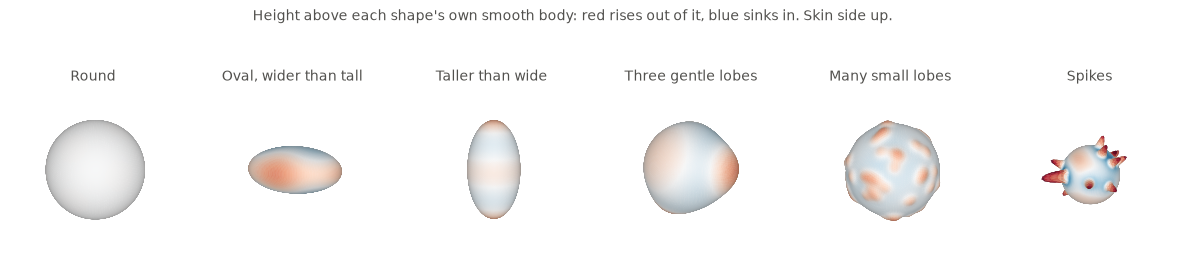

,Round,"Oval, wider than tall",Taller than wide,Three gentle lobes,Many small lobes,Spikes
Spectral roundness S,1.000,0.757,0.789,0.899,0.617,0.246
Bending W / 4π,1.000,1.275,1.189,1.116,1.629,4.140
Area beyond degree 1,0.000,0.043,0.039,0.013,0.020,0.131
Lobes,1.000,1.000,2.000,3.000,15.000,12.000
Depth share,0.333,0.154,0.587,0.335,0.331,0.288
Tilt (°),1.751,0.000,90.000,20.572,22.207,14.571


In [3]:
def bumps(directions, height, width, subdivisions=5, scale=(1, 1, 1)):
    s = trimesh.creation.icosphere(subdivisions=subdivisions); u = s.vertices / np.linalg.norm(s.vertices, axis=1, keepdims=True)
    gain = sum(height * np.exp(-np.linalg.norm(u - np.asarray(d) / np.linalg.norm(d), axis=1) ** 2 / (2 * width ** 2)) for d in directions) if len(directions) else 0 * u[:, 0]
    return trimesh.Trimesh(u * (1 + gain)[:, None] * np.asarray(scale), s.faces, process=False)
rng = np.random.default_rng(1)
shapes = {"Round": bumps([], 0, 1), "Oval, wider than tall": bumps([], 0, 1, scale=(1.5, .7, 1.1)), "Taller than wide": bumps([], 0, 1, scale=(.8, 1.5, .8)), "Three gentle lobes": bumps([(1, 0, 0), (-.5, .8, .2), (-.3, -.6, .8)], .28, .38),
          "Many small lobes": bumps(rng.normal(size=(60, 3)), .06, .1), "Spikes": bumps(rng.normal(size=(14, 3)), .45, .07)}
fig, axes = plt.subplots(1, 6, figsize=(15, 3.1), subplot_kw=dict(projection="3d")); table = {}
for ax, (name, m) in zip(axes, shapes.items()):
    s = mesh_spectrum(m, 200); h = surface_height(m, s["phi"], s["c"]) / np.sqrt(m.area / (4 * np.pi)); sg = surface_signs(m, s, 1)
    draw_mesh(ax, upright(m), h, cmap="RdBu_r", vmin=-.15, vmax=.15, view=(8, -60)); ax.set_title(name, fontsize=10, color=INK)
    table[name] = {"Spectral roundness S": sg["roundness"], "Bending W / 4π": sg["bending"], "Area beyond degree 1": 1 - sg["budget"][0], "Lobes": sg["lobes"], "Depth share": sg["depth_share"], "Tilt (°)": sg["tilt"]}
fig.suptitle("Height above each shape's own smooth body: red rises out of it, blue sinks in. Skin side up.", fontsize=10, color=INK, y=1.02); fig.savefig(A + "shapes.png", dpi=150, bbox_inches="tight"); plt.show()
display(pd.DataFrame(table).round(3))

**The area budget on real lesions.** Where each surface spends its area. The two synthetic shapes are from the figure above; the real lines are medians over Train+Validation.

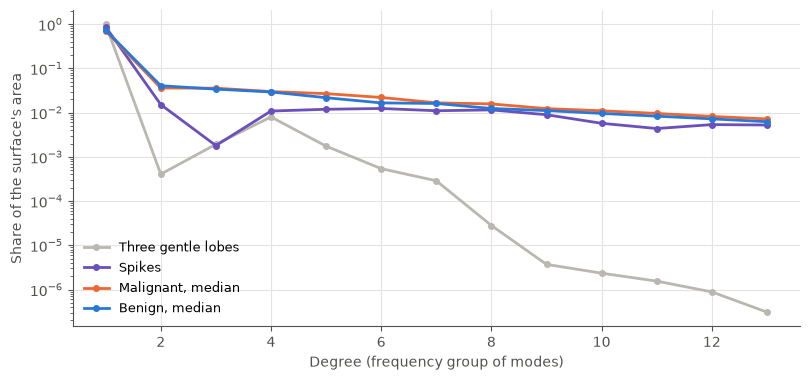

Median area beyond degree 1, Train+Validation: 0.293 ; modes kept account for a median 0.952 of the area


In [4]:
fig, ax = plt.subplots(figsize=(8.2, 3.9)); degrees = np.arange(1, 14)
for name, colour in (("Three gentle lobes", MUTED), ("Spikes", PURPLE)):
    m = shapes[name]; sp = mesh_spectrum(m, 200); ax.plot(degrees, area_budget(sp["lam"], sp["c"], m.area), color=colour, lw=2, marker="o", ms=4, label=name)
d = np.load(O + "features.npz"); keep = ~d["test"]
for label, name, colour in ((1, "Malignant, median", ORANGE), (0, "Benign, median", BLUE)):
    ax.plot(degrees, np.median(d["budget"][keep & (d["y"] == label), 0], axis=0), color=colour, lw=2, marker="o", ms=4, label=name)
ax.set_yscale("log"); ax.set(xlabel="Degree (frequency group of modes)", ylabel="Share of the surface's area"); ax.legend(frameon=False, fontsize=9, loc="lower left"); fig.tight_layout(); fig.savefig(A + "budget.png", dpi=150, bbox_inches="tight"); plt.show()
print("Median area beyond degree 1, Train+Validation:", round(float(np.median(1 - d["budget"][keep, 0, 0])), 3), "; modes kept account for a median", round(float(np.median(d["budget"][keep, 0].sum(1))), 3), "of the area")

The two classes are close at every degree. Real masks also spend more area at high degrees than our spiked shape: a median of 29% beyond degree 1, against 13%. All these masks are rough at fine scales, and some of that may come from drawing them slice by slice. This roughness is common to both classes, so the class difference has to be found on top of it.

## 5. Real lesions in 3D

Six Train lesions, picked by a fixed rule: the 25th, 50th and 75th volume percentiles of each class. They show what the descriptors measure and are not evidence of a class difference. Skin side up.

**Top row, height above the lesion's own smooth body.** Red rises out of it, blue sinks in. **Bottom row, tissue lines carried onto the surface.** Orange means nearby lines run out of the lesion, purple means they run along it.

All six are far from a textbook oval, benign ones included. Counts of lobes overlap: 15–19 on these benign lesions, 19–27 on these malignant ones.

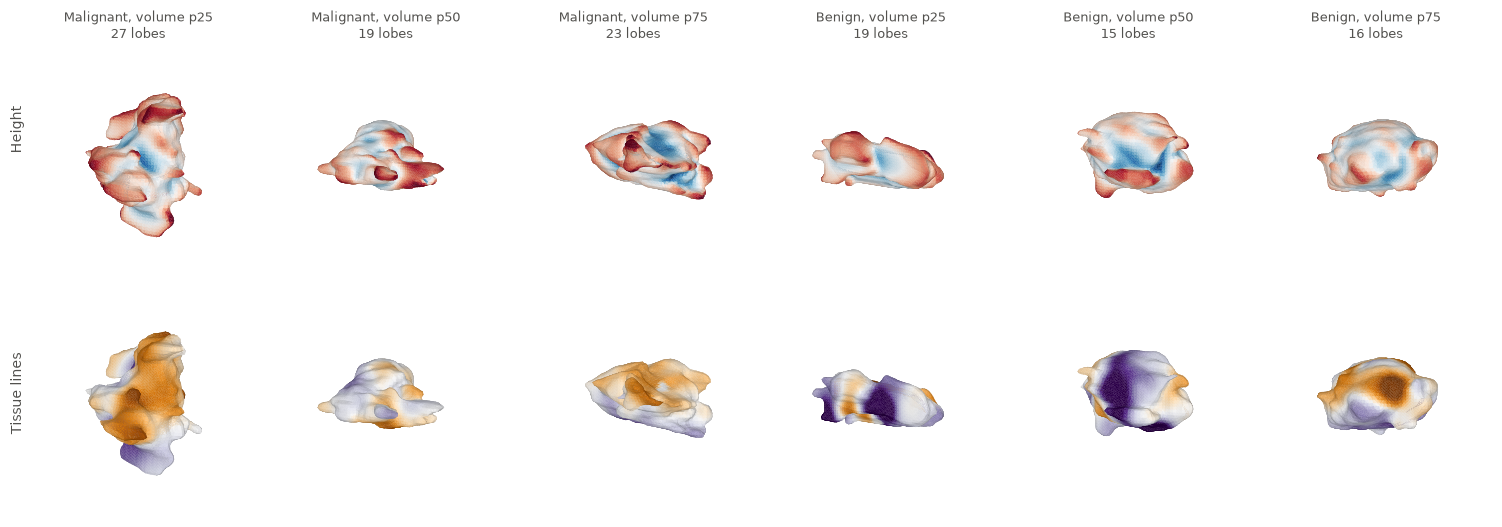

In [5]:
keys = [f"{c}{q}" for c in ("malignant", "benign") for q in (25, 50, 75)]
fig = plt.figure(figsize=(15, 5.4))
for i, k in enumerate(keys):
    m = sample_mesh(k); ax = fig.add_subplot(2, 6, i + 1, projection="3d"); draw_mesh(ax, upright(m), samples[k + "_height"], cmap="RdBu_r", vmin=-.2, vmax=.2, view=(12, -55))
    tops = m.vertices[samples[k + "_peaks"]]; ax.set_title(f"{k[:-2].capitalize()}, volume p{k[-2:]}\n{len(tops)} lobes", fontsize=9, color=INK)
    ax = fig.add_subplot(2, 6, i + 7, projection="3d"); draw_mesh(ax, upright(m), np.nan_to_num(samples[k + "_field"]), cmap="PuOr_r", vmin=-.12, vmax=.12, view=(12, -55))
fig.text(0.002, .72, "Height", rotation=90, color=INK, fontsize=10); fig.text(0.002, .2, "Tissue lines", rotation=90, color=INK, fontsize=10)
fig.tight_layout(); fig.savefig(A + "surfaces.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Is spiculation just spikes on the boundary?

**Partly.** A spicule is a thin line radiating from the margin, but on this data it is not a spike on the mask's boundary.

- **Tan's feature never reads the boundary.** It finds bright lines in coronal planes of the image, up to 30 mm from each site, and counts how many point at that site (`features/tan/spiculation.py`). The mask only decides where that map gets summarised.
- **Spicules are not only tumour.** In malignant lesions they come from infiltration, a desmoplastic response or periductal fibrosis [6].

If spiculation were spikes on the mask, three things should hold. Surface bumps should track Tan's spiculation, bumps should sit where lines leave the surface, and the class signal should stop at the surface. All three can be tested.

**How the lines are read.** Each panel is the coronal plane where the lesion is widest, with the strongest 12% of line responses in the 2–10 mm shell, at every second pixel. Here a line counts as running outward if it lies within 45° of the direction away from the lesion. **Single planes do not show the class difference by eye**: the median malignant lesion has 47% and the median benign lesion 61%. The real measure is a small average, about 0.02 above chance on a scale where chance is near 0.64, taken over every line in every plane.

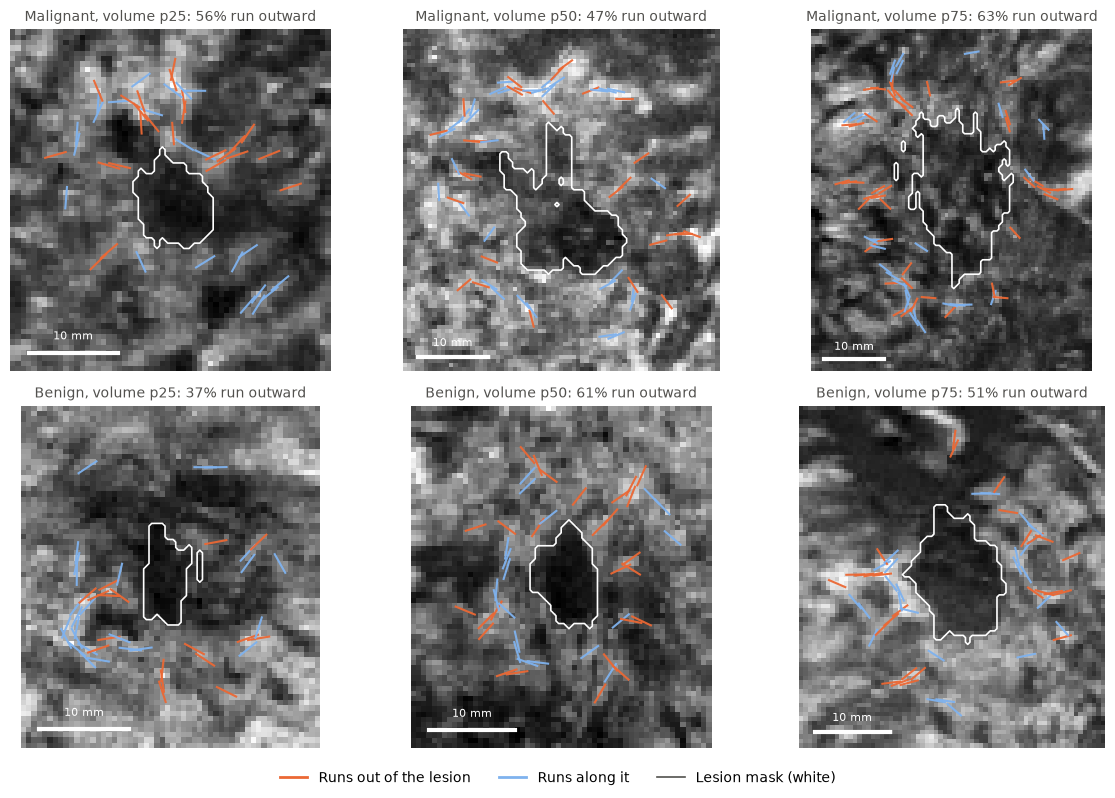

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, k in zip(axes.ravel(), [f"{c}{q}" for c in ("malignant", "benign") for q in (25, 50, 75)]):
    image, mask, theta, strength, pixel = samples[k + "_image"], samples[k + "_mask"], samples[k + "_theta"], samples[k + "_strength"], samples[k + "_pixel"]
    distance, (near_r, near_c) = ndimage.distance_transform_edt(~mask, sampling=pixel, return_indices=True)
    shell = (distance >= 2) & (distance < 10); strong = shell & (strength > np.percentile(strength[shell], 88))
    r, c = np.nonzero(strong); take = (r % 2 == 0) & (c % 2 == 0); r, c = r[take], c[take]
    excess = np.abs(np.cos(theta[r, c] - np.arctan2(c - near_c[r, c], r - near_r[r, c])))
    half = 2.2; ends = lambda sign: np.c_[c + sign * half * np.sin(theta[r, c]), r + sign * half * np.cos(theta[r, c])]
    ax.imshow(image, cmap="gray", origin="lower"); ax.contour(mask, [.5], colors="white", linewidths=1.2)
    ax.add_collection(LineCollection(np.stack([ends(-1), ends(1)], 1), colors=np.where(excess > np.sqrt(.5), ORANGE, "#7fb2ee"), linewidths=1.5, alpha=.95)); ax.set_axis_off()
    outward = np.average(excess > np.sqrt(.5), weights=strength[r, c]); ax.set_title(f"{k[:-2].capitalize()}, volume p{k[-2:]}: {outward:.0%} run outward", fontsize=10, color=INK)
    bar = 10 / pixel[1]; ax.plot([3, 3 + bar], [3, 3], color="white", lw=3); ax.text(3 + bar / 2, 5.5, "10 mm", color="white", ha="center", fontsize=8)
fig.legend(handles=[Line2D([], [], color=ORANGE, lw=2, label="Runs out of the lesion"), Line2D([], [], color="#7fb2ee", lw=2, label="Runs along it"), Line2D([], [], color=INK, lw=1.2, label="Lesion mask (white)")], loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, .04, 1, 1)); fig.savefig(A + "planes.png", dpi=150, bbox_inches="tight"); plt.show()

**Do bumps track spiculation, and do they sit where lines leave?** All correlations are after removing volume.

In [7]:
s = overlap.loc[[c for c in overlap.index if c.startswith(("Radial", "Irregularity: log bending", "Lobes: log lobes", "Orientation"))], ["Spiculation: SP90", "Spiculation: SPcyl_upper_mean", "Intensity: MC", "Intensity: PAB", "Intensity: H", "Classical shape: VHWR"]].round(2); display(s)
print("Surface signs against SP90, after volume: strongest |rho| =", round(overlap.loc[[c for c in overlap.index if c.startswith(("Irregularity", "Lobes"))], "Spiculation: SP90"].abs().max(), 2))
print("Radial lines against SP90, after volume:", overlap.loc[[c for c in overlap.index if c.startswith("Radial")], "Spiculation: SP90"].round(2).to_dict())
print("Do surface bumps sit where lines run out, within one lesion? Median Spearman:", {k: round(coupling[k], 3) for k in ("malignant", "benign")}, "; as a classifier, AUC", round(coupling["auc"][0], 3))

,Spiculation: SP90,Spiculation: SPcyl_upper_mean,Intensity: MC,Intensity: PAB,Intensity: H,Classical shape: VHWR
Irregularity: log bending,0.35,0.29,0.29,-0.19,0.17,0.26
Lobes: log lobes,0.34,0.27,0.20,-0.22,0.08,0.27
Orientation: logit depth share,0.07,0.03,0.20,-0.23,-0.30,0.90
Orientation: tilt,0.10,0.07,0.10,-0.16,-0.10,0.72
Radial lines: mean,0.77,0.66,0.04,-0.12,0.23,0.20
Radial lines: skin side,0.72,0.69,0.06,-0.09,0.22,0.22
Radial lines: strongest tenth,0.73,0.63,0.02,-0.06,0.23,0.11
Radial lines: share outward,0.77,0.66,0.00,-0.10,0.23,0.20


Surface signs against SP90, after volume: strongest |rho| = 0.36
Radial lines against SP90, after volume: {'Radial lines: mean': 0.77, 'Radial lines: skin side': 0.72, 'Radial lines: strongest tenth': 0.73, 'Radial lines: share outward': 0.77}
Do surface bumps sit where lines run out, within one lesion? Median Spearman: {'malignant': 0.057, 'benign': 0.076} ; as a classifier, AUC 0.533


The surface signs reach a Spearman of at most 0.36 with SP90, while radial lines reach 0.72–0.77. So radial lines and Tan's spiculation read much the same tissue pattern, and mask bumps do not. Within a single lesion, bumps barely sit where lines run out: median Spearman 0.06 for malignant and 0.08 for benign lesions. Radial lines are also close to independent of margin contrast (0.04) and posterior behaviour (−0.12).

**Does the signal stop at the surface?** The excess is measured at growing distance from the mask, out to 30 mm. As a control, the same measure runs on a **sham lesion**: the same mask moved to other tissue in the same scan, with 40 mm between the two masks, so that their 10 mm shells stay 20 mm apart. If scanner settings or general breast texture produced the signal, sham lesions would separate the classes too. This control and the 30 mm profile were added after the first results.

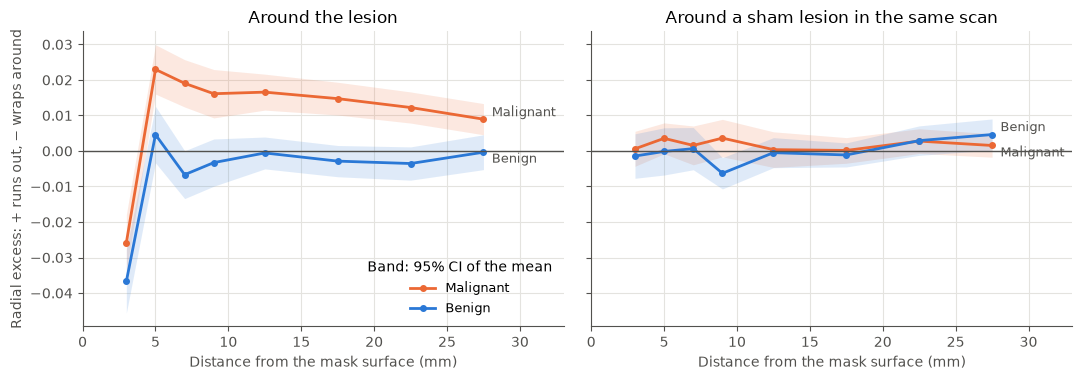

Lesions with room for a sham: 99 of 130, median 1.5 sites each
AUC at the lesion, those lesions: 0.780; at the sham: 0.585 (95% CI 0.473-0.696); difference 0.195 (0.053 to 0.337)
AUC at the lesion, all 130: 0.742; dark lines instead of bright: 0.689; Spearman bright with dark 0.60, lesion with sham 0.14, this crop with the stored feature 0.985


In [8]:
def plot_reach(table, file):
    shells = sorted(set(table.index.get_level_values(2)), key=lambda s: float(s.split("-")[0])); mid = [np.mean([float(x) for x in s.replace(" mm", "").split("-")]) for s in shells]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
    for ax, place, title in ((axes[0], "lesion", "Around the lesion"), (axes[1], "sham", "Around a sham lesion in the same scan")):
        for label, colour in (("malignant", ORANGE), ("benign", BLUE)):
            t = table.loc[(place, label)].loc[shells]; ax.plot(mid, t["mean"], color=colour, lw=2, marker="o", ms=4, label=label.capitalize()); ax.fill_between(mid, t["mean"] - 1.96 * t["se"], t["mean"] + 1.96 * t["se"], color=colour, alpha=.15, lw=0)
            other = table.loc[(place, "benign" if label == "malignant" else "malignant")].loc[shells, "mean"].iloc[-1]
            ax.annotate(label.capitalize(), (mid[-1], t["mean"].iloc[-1]), xytext=(6, 5 if t["mean"].iloc[-1] > other else -5), textcoords="offset points", color=INK, va="center", fontsize=9)
        ax.axhline(0, color=INK, lw=1); ax.set(title=title, xlabel="Distance from the mask surface (mm)"); ax.set_xlim(0, 33)
    axes[0].set_ylabel("Radial excess: + runs out, − wraps around"); axes[0].legend(frameon=False, fontsize=9, loc="lower right", title="Band: 95% CI of the mean"); fig.tight_layout(); fig.savefig(file, dpi=150, bbox_inches="tight"); plt.show()
plot_reach(reach, A + "reach.png")
g = control["lesion_minus_sham"]; print(f"Lesions with room for a sham: {control['with_sham']} of {control['lesions']}, median {control['median_shams']} sites each")
print(f"AUC at the lesion, those lesions: {control['auc_lesion_same_lesions'][0]:.3f}; at the sham: {control['auc_sham'][0]:.3f} (95% CI {control['sham_auc_low']:.3f}-{control['sham_auc_high']:.3f}); difference {g['gain']:.3f} ({g['low']:.3f} to {g['high']:.3f})")
print(f"AUC at the lesion, all 130: {control['auc_lesion'][0]:.3f}; dark lines instead of bright: {control['auc_dark'][0]:.3f}; Spearman bright with dark {control['rho_bright_dark']:.2f}, lesion with sham {control['rho_lesion_sham']:.2f}, this crop with the stored feature {control['rho_stored']:.3f}")

- **Beyond 4 mm, malignant lesions stay above zero out to 25–30 mm** (0.023 falling to 0.009), and benign lesions stay near zero. A pattern 30 mm long is not a spike on a boundary. It looks more like tissue drawn toward the lesion, as in the retraction phenomenon [10]. Without histology we cannot say which structures form these lines.
- **Sham lesions sit near zero in both classes.** On the 99 lesions with room for one, AUC is 0.78 at the lesion and 0.58 at the sham (95% CI 0.47–0.70); the difference is 0.20 (0.05–0.34). So the signal is tied to where the lesion is. A small effect across the whole scan cannot be excluded.
- **In the first shell, 2–4 mm, lines run along the surface in both classes** (−0.026 and −0.037). That could be tissue pushed aside, as in [4], or the detector's response to the lesion's own edge; at σ = 0.9 mm we cannot separate them. So this does not show that benign lesions wrap tissue around them: beyond 4 mm they are neutral.
- **Dark lines show the same thing, more weakly:** AUC 0.69, Spearman 0.60 with bright lines. Tan's choice of bright lines is not critical.

**Answer.** Clinically a spicule is a line from the margin. What predicts malignancy here is a convergence of tissue lines reaching far beyond the annotated surface, and mask bumps do not track it. One limit: masks are drawn at limited resolution, so thin strands attached to the real tumour surface are probably left out of them. These data cannot tell "no spike there" from "spike not annotated".

## 7. Which signs separate the classes

Single features first. "After volume" uses the residual against log volume. These are plain AUCs on all 130 lesions, with the direction taken from the data, so they are slightly generous.

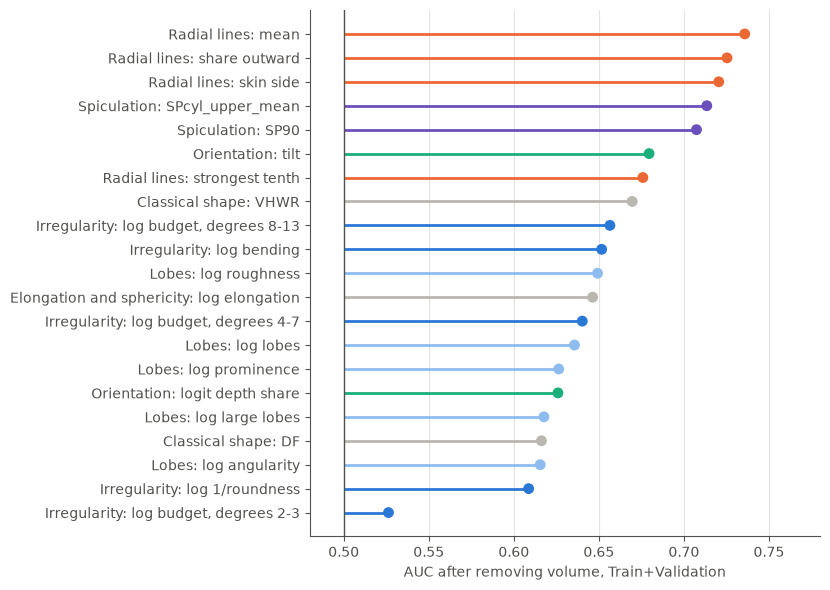

,AUC,Toward malignant,AUC after volume,ρ volume,ρ SP90 (after volume),ρ VHWR (after volume),ICC 0.5 mm,ICC 1 mm
Irregularity: log 1/roundness,0.593,+,0.609,-0.001,0.363,-0.004,0.833,0.516
Irregularity: log bending,0.639,+,0.652,-0.020,0.349,0.262,0.867,0.556
"Irregularity: log budget, degrees 2-3",0.544,-,0.526,-0.108,0.180,-0.221,0.815,0.471
"Irregularity: log budget, degrees 4-7",0.596,+,0.640,-0.185,0.258,0.311,0.863,0.444
"Irregularity: log budget, degrees 8-13",0.661,+,0.656,0.080,0.341,0.246,0.843,0.509
Lobes: log lobes,0.666,+,0.636,0.131,0.337,0.266,0.777,0.579
Lobes: log large lobes,0.584,+,0.618,-0.046,0.204,0.297,0.595,0.430
Lobes: log prominence,0.666,+,0.626,0.193,0.325,0.321,0.860,0.653
Lobes: log roughness,0.611,+,0.649,-0.149,0.253,0.299,0.838,0.380
Lobes: log angularity,0.634,+,0.616,0.110,0.321,0.197,0.639,0.422


In [9]:
show = single.loc[[c for c in single.index if not c.startswith("Tips") and not c.startswith("Hersch")]].sort_values("auc_after_volume")
family = lambda c: c.split(": ")[0]; colour = {"Radial lines": ORANGE, "Spiculation": PURPLE, "Orientation": AQUA, "Classical shape": MUTED, "Elongation and sphericity": MUTED, "Irregularity": BLUE, "Lobes": "#8fbcee"}
fig, ax = plt.subplots(figsize=(8.4, 6)); ax.hlines(show.index, .5, show.auc_after_volume, color=[colour[family(c)] for c in show.index], lw=2); ax.scatter(show.auc_after_volume, show.index, color=[colour[family(c)] for c in show.index], s=46, zorder=3)
ax.axvline(.5, color=INK, lw=1); ax.set(xlabel="AUC after removing volume, Train+Validation", xlim=(.48, .78)); ax.grid(axis="y", visible=False); fig.tight_layout(); fig.savefig(A + "features.png", dpi=150, bbox_inches="tight"); plt.show()
display(single[["auc", "sign", "auc_after_volume", "rho_volume", "rho_sp90", "rho_vhwr", "icc_0.5", "icc_1.0"]].rename(columns={"auc": "AUC", "sign": "Toward malignant", "auc_after_volume": "AUC after volume", "rho_volume": "ρ volume", "rho_sp90": "ρ SP90 (after volume)", "rho_vhwr": "ρ VHWR (after volume)", "icc_0.5": "ICC 0.5 mm", "icc_1.0": "ICC 1 mm"}).round(3))

- **Radial lines lead after volume**, 0.736 against 0.707 for SP90. SP90 is higher raw, 0.800 against 0.741, but it also follows size (Spearman 0.40 against 0.04), so part of its lead is size.
- **Tilt is a separate signal:** 0.68 after volume, Spearman 0.10 with SP90. Depth share is nearly Tan's height-to-width ratio (0.90).
- **The designed surface signs beat the earlier spectral ones, modestly:** fine area budget 0.656 and bending 0.652, against tips 0.618 and the Hersch ratio 0.592.

Next, families and models, with logistic regression over 20 repeats of five-fold CV. Intervals are bootstrap 95% over lesions, for one comparison each.

In [10]:
display(pd.DataFrame({g: {"Alone": e["alone"], "After size": e["after_size"], "Size → size + family": e["with_size"]["after"], "Gain": e["with_size"]["gain"], "Gain low": e["with_size"]["low"], "Gain high": e["with_size"]["high"],
                         "Added to size + spiculation": e["add_to_base"]["after"], "Gain over it": e["add_to_base"]["gain"], "Low": e["add_to_base"]["low"], "High": e["add_to_base"]["high"], "Shuffled p": e["shuffled_p"]} for g, e in effects.items()}).T.round(3))
display(models.round(3))
display(pd.DataFrame(comparisons).T[["before", "after", "gain", "low", "high"]].round(3))
print("Group selection inside CV:", {k: (round(v, 3) if isinstance(v, float) else {a: round(b, 2) for a, b in v.items()}) for k, v in selection.items()})

,Alone,After size,Size → size + family,Gain,Gain low,Gain high,Added to size + spiculation,Gain over it,Low,High,Shuffled p
Irregularity,0.649,0.642,0.754,0.046,-0.014,0.107,0.834,0.036,-0.001,0.076,0.005
Lobes,0.600,0.622,0.736,0.028,-0.032,0.087,0.792,-0.006,-0.032,0.019,0.274
Orientation,0.597,0.649,0.757,0.049,-0.010,0.112,0.825,0.027,-0.011,0.065,0.005
Radial lines,0.763,0.705,0.805,0.097,0.026,0.171,0.797,-0.001,-0.025,0.023,0.239


,n,auc,acc,auc_forest
Size,2.0,0.707,0.684,0.637
Size + spiculation,8.0,0.795,0.737,0.801
Size + VHWR,3.0,0.755,0.703,0.678
Size + spiculation + VHWR,9.0,0.814,0.751,0.798
Size + surface signs (mask and beam),14.0,0.765,0.706,0.669
Size + radial lines,6.0,0.803,0.713,0.744
Size + spiculation + radial lines,12.0,0.792,0.732,0.791
Size + orientation + radial lines,8.0,0.827,0.753,0.760
Size + spiculation + orientation + radial lines,14.0,0.820,0.745,0.796
Size + all designed,18.0,0.814,0.731,0.760


,before,after,gain,low,high
Size + radial lines vs size + spiculation,0.798,0.805,0.007,-0.039,0.057
Size + orientation + radial lines vs size + spiculation,0.798,0.832,0.035,-0.015,0.087
Size + orientation + radial lines vs size,0.708,0.832,0.125,0.051,0.204
Size + surface signs vs size,0.708,0.772,0.064,-0.008,0.142
Hybrid vs size + spiculation,0.798,0.835,0.038,-0.010,0.089
Hybrid vs size,0.708,0.835,0.128,0.054,0.205
Fine budget added to the hybrid,0.835,0.835,0.000,-0.026,0.024


Group selection inside CV: {'auc': 0.798, 'picked': {'Size': 0.93, 'Spiculation': 0.67, 'Irregularity': 0.53, 'Orientation': 0.52, 'Radial lines': 0.51, 'Lobes': 0.04}}


- **The surface alone is weak.** All surface signs with the beam, without size or the image: AUC 0.634, ACC 0.599. Adding size gives 0.765 and 0.706; size alone gives 0.707 and 0.684.
- **Radial lines can replace Tan's spiculation.** Alone: AUC 0.763 against 0.766. With size: 0.803 against 0.795. Added on top of size and spiculation, they contribute −0.001, because the two overlap.
- **Two families may add to size and spiculation.** Irregularity adds 0.036 (−0.001 to 0.076) and orientation 0.027 (−0.011 to 0.065). Each beats shuffled copies of itself (p = 0.005), but each interval includes zero and four families were tried. The Hersch ratio's similar gain on these lesions did not replicate on Test, so these are leads. Lobes add nothing (−0.006).
- **AUC passes 0.80 and ACC does not.** Size, radial lines and tilt reach AUC 0.835 and ACC 0.759, against 0.795 and 0.737 for size and spiculation. The AUC gain is 0.038 (−0.010 to 0.089), so it is **not established**.
- **The lead depends on the classifier.** With a random forest the order reverses: 0.739 against 0.801.

ROC curves from the mean out-of-fold score, then the table of other shells.

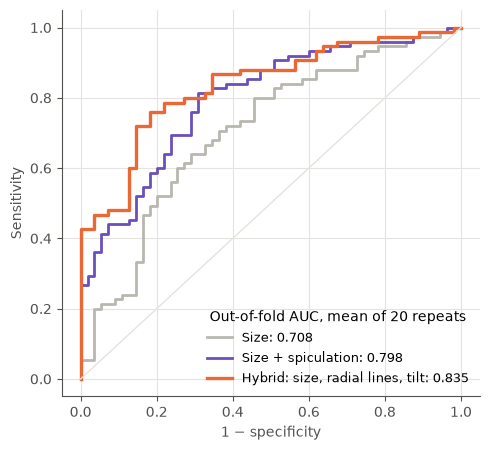

At p >= 0.5, from the mean score over repeats:


,Sensitivity,Specificity,ACC
Size,0.787,0.545,0.685
Size + spiculation,0.813,0.673,0.754
"Hybrid: size, radial lines, tilt",0.827,0.655,0.754
Hybrid + fine budget (LB),0.827,0.673,0.762


Other shells for the line excess, tried after the distance profile was seen:


,AUC,AUC after volume,ρ volume,With size and tilt: AUC,With size and tilt: ACC
"2-10 mm, as designed",0.741,0.736,0.040,0.835,0.759
2-4 mm,0.600,0.607,0.012,0.761,0.709
4-6 mm,0.669,0.678,-0.032,0.812,0.716
6-8 mm,0.739,0.719,0.075,0.827,0.746
8-10 mm,0.696,0.659,0.147,0.793,0.728
10-15 mm,0.727,0.674,0.281,0.801,0.714
15-20 mm,0.754,0.683,0.269,0.827,0.753
20-25 mm,0.737,0.682,0.207,0.821,0.749
25-30 mm,0.648,0.626,0.109,0.788,0.733
4-10 mm,0.753,0.738,0.084,0.830,0.748


In [11]:
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
scores = pd.read_csv(O + "scores.csv"); y = scores.y.values
fig, ax = plt.subplots(figsize=(5, 4.6))
for name, colour, lw in (("Size", MUTED, 2), ("Size + spiculation", PURPLE, 2), ("Hybrid: size, radial lines, tilt", ORANGE, 2.4)):
    fpr, tpr, _ = roc_curve(y, scores[name]); ax.plot(fpr, tpr, color=colour, lw=lw, label=f"{name}: {roc_auc_score(y, scores[name]):.3f}")
ax.plot([0, 1], [0, 1], color=GRID, lw=1); ax.set(xlabel="1 − specificity", ylabel="Sensitivity"); ax.legend(frameon=False, fontsize=9, loc="lower right", title="Out-of-fold AUC, mean of 20 repeats"); fig.tight_layout(); fig.savefig(A + "roc.png", dpi=150, bbox_inches="tight"); plt.show()
rows_cm = {}
for name in ("Size", "Size + spiculation", "Hybrid: size, radial lines, tilt", "Hybrid + fine budget (LB)"):
    tn, fp, fn, tp = confusion_matrix(y, scores[name] > 0).ravel(); rows_cm[name] = {"Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp), "ACC": (tp + tn) / len(y)}
print("At p >= 0.5, from the mean score over repeats:"); display(pd.DataFrame(rows_cm).T.round(3)); print("Other shells for the line excess, tried after the distance profile was seen:"); display(pd.read_csv(O + "reach.csv", index_col=0).round(3).rename(columns={"auc": "AUC", "auc_after_volume": "AUC after volume", "rho_volume": "ρ volume", "hybrid_auc": "With size and tilt: AUC", "hybrid_acc": "With size and tilt: ACC"}))

The curves separate most at low false-positive rates. These accuracies come from the mean score over repeats, so they differ slightly from the per-repeat means in the table above, and on them the hybrid and size + spiculation tie at 0.754.

**Exploratory: a wider shell.** Using all of 4–30 mm gives AUC 0.847 and ACC 0.782 with size and tilt. It was tried after seeing the distance profile, it picks up some size (Spearman 0.18), and no version reaches ACC 0.80. It is a lead for new data, not a result.

### The hybrid: three numbers

The model is size, lines leaving the surface, and tilt to the skin. It is stored in `results/lb-malignancy/frozen.json`. Section 9 scores it once on Test, where the tilt term does not hold up.

How it was narrowed: one feature per family was picked inside each training fold, which gives the honest estimate, **AUC 0.820 and ACC 0.738 out of fold**. Refitting showed roughness doing nothing (odds ratio 1.01), and the fine area budget adding 0.000 (−0.026 to 0.024; p = 0.24 against shuffled copies), so both were removed. That narrowing used these lesions, so the 0.835 above is optimistic.

**Explaining one prediction.** Each bar is a feature's contribution to the log-odds; orange pushes toward malignant. The model was fitted on these same lesions, so these are illustrations, not out-of-fold scores.

,Odds ratio per SD,Mean,SD
Size: log volume,2.990,6.593,1.444
Radial lines: mean,2.861,0.002,0.024
Orientation: tilt,1.988,10.520,12.242


Inside-fold procedure, one feature per family, out of fold: AUC 0.820, ACC 0.738; against size + spiculation {'before': 0.798, 'after': 0.821, 'gain': 0.024, 'low': -0.027, 'high': 0.076}
How often each feature was picked: {'Orientation: tilt': 1.0, 'Radial lines: mean': 0.78, 'Irregularity: log budget, degrees 8-13': 0.73, 'Lobes: log roughness': 0.7, 'Lobes: log lobes': 0.21, 'Irregularity: log bending': 0.17, 'Radial lines: share outward': 0.14, 'Irregularity: log budget, degrees 4-7': 0.1, 'Radial lines: skin side': 0.08, 'Lobes: log large lobes': 0.07, 'Lobes: log angularity': 0.01, 'Lobes: log prominence': 0.01}
Fine budget added to the hybrid: {'before': 0.835, 'after': 0.835, 'gain': 0.0, 'low': -0.026, 'high': 0.024} ; p against shuffled copies of it 0.24


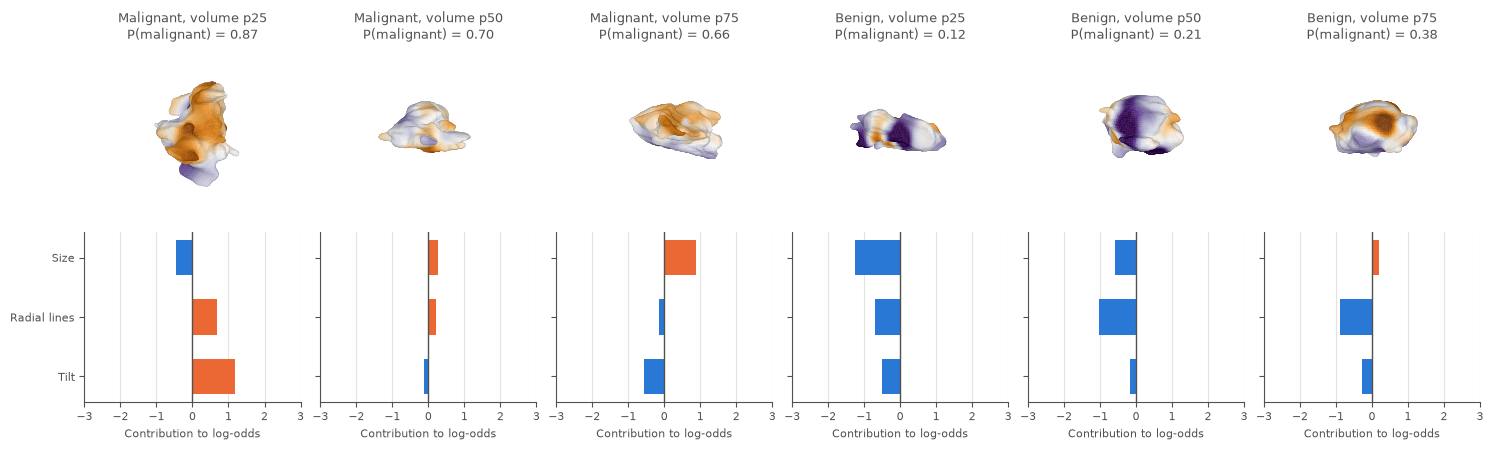

In [12]:
display(pd.DataFrame({"Odds ratio per SD": np.exp(frozen["coefficients"]), "Mean": frozen["mean"], "SD": frozen["scale"]}, index=frozen["features"]).round(3))
print(f"Inside-fold procedure, one feature per family, out of fold: AUC {frozen['procedure_auc']:.3f}, ACC {frozen['procedure_acc']:.3f}; against size + spiculation", {k: round(v, 3) for k, v in frozen["procedure_against_size_spiculation"].items()})
print("How often each feature was picked:", {k: round(v, 2) for k, v in frozen["picked"].items()})
print("Fine budget added to the hybrid:", {k: round(v, 3) for k, v in comparisons["Fine budget added to the hybrid"].items()}, "; p against shuffled copies of it", round(frozen["fine_budget_shuffled_p"], 2))
coef, mean, scale = (np.array(frozen[k]) for k in ("coefficients", "mean", "scale")); names = frozen["features"]; short = ["Size", "Radial lines", "Tilt"]
picks = [f"{c}{q}" for c in ("malignant", "benign") for q in (25, 50, 75)]
fig = plt.figure(figsize=(15, 4.6))
for i, k in enumerate(picks):
    row = rows.iloc[int(samples[k + "_index"])]; assert row.y == (k.startswith("malignant")); z = (row[names].values.astype(float) - mean) / scale; parts = coef * z; total = frozen["intercept"] + parts.sum()
    ax = fig.add_subplot(2, 6, i + 1, projection="3d"); draw_mesh(ax, upright(sample_mesh(k)), np.nan_to_num(samples[k + "_field"]), cmap="PuOr_r", vmin=-.12, vmax=.12, view=(12, -55)); ax.set_title(f"{k[:-2].capitalize()}, volume p{k[-2:]}\nP(malignant) = {1 / (1 + np.exp(-total)):.2f}", fontsize=9, color=INK)
    ax = fig.add_subplot(2, 6, i + 7); ax.barh(short[::-1], parts[::-1], color=[ORANGE if p > 0 else BLUE for p in parts[::-1]], height=.6); ax.axvline(0, color=INK, lw=1); ax.set_xlim(-3, 3); ax.set_xlabel("Contribution to log-odds", fontsize=8); ax.tick_params(labelsize=8); ax.grid(axis="y", visible=False)
    if i: ax.set_yticklabels([])
fig.tight_layout(); fig.savefig(A + "explain.png", dpi=150, bbox_inches="tight"); plt.show()

**What Laplace–Beltrami contributes**, plainly:

| Piece | Uses LB? | Result |
|---|---|---|
| Eigenvalues | Yes | Nothing beyond volume (earlier steps) |
| Area budget, bending, roundness | Operator on the coordinates | AUC after volume up to 0.66; beats eigenvalues; adds 0.000 once lines and tilt are in |
| Lobes | Modes for the body, plus persistence | Adds nothing |
| Tilt, depth share | Low modes | The same as surface PCA: within 0.1° on the six sample lesions |
| Line excess, mean | **No** | The strongest new feature |
| Line field on the surface | Heat kernel | The same power as the mean; gives the 3D maps |

**So on these lesions the hybrid's signal does not come from the LB operator.** LB gives a well-founded measure of surface irregularity, and a way to put image evidence on the surface and show it. The class signal comes from the tissue around the lesion, its tilt and its size. Section 9 tests this on Test.

## 8. Reliability

ICC under simulated boundary noise on Train+Validation, as in `lb-stability.ipynb`, and rank between true and predicted masks: Zhou 2021's masks, 3 seeds, on Test patches centred on the true lesion. Only geometry and image are used there, and Test labels are not read.

In [13]:
t = single.loc[[c for c in single.index if c in predicted.index], ["icc_0.25", "icc_0.5", "icc_1.0"]].join(predicted[["rank", "misses"]]).rename(columns={"icc_0.25": "ICC 0.25 mm", "icc_0.5": "ICC 0.5 mm", "icc_1.0": "ICC 1 mm", "rank": "True vs predicted mask, rank", "misses": "Misses of 210"}); display(t.round(3))

,ICC 0.25 mm,ICC 0.5 mm,ICC 1 mm,"True vs predicted mask, rank",Misses of 210
Irregularity: log 1/roundness,0.980,0.833,0.516,0.213,4.0
Irregularity: log bending,0.984,0.867,0.556,0.221,4.0
"Irregularity: log budget, degrees 2-3",0.964,0.815,0.471,0.268,4.0
"Irregularity: log budget, degrees 4-7",0.975,0.863,0.444,0.276,4.0
"Irregularity: log budget, degrees 8-13",0.976,0.843,0.509,0.163,4.0
Lobes: log lobes,0.928,0.777,0.579,0.233,4.0
Lobes: log large lobes,0.871,0.595,0.430,0.190,4.0
Lobes: log prominence,0.978,0.860,0.653,0.001,4.0
Lobes: log roughness,0.967,0.838,0.380,0.223,4.0
Lobes: log angularity,0.913,0.639,0.422,0.183,4.0


- **Radial lines barely depend on the mask:** ICC 0.96–0.98 at 0.5 mm, and rank 0.80–0.84 on predicted masks. Most of the shell is far from the boundary, so an imperfect mask changes little.
- **Orientation partly survives:** rank 0.72 for depth share and 0.43 for tilt.
- **Surface signs pass simulated noise and fail real masks:** ICC 0.60–0.87 at 0.5 mm, much better than 0.13 for eigenvalue k = 100, but rank only 0.00–0.28 on predicted masks. A network's masks do not reproduce a lesion's fine surface, and simulated noise misses that.
- **These are ranks, not class results.** Section 9 measures AUC and ACC on predicted masks, on Test.

## 9. One second look at Test

**What this is, and what it cannot be.** `lb-feature-evaluation.ipynb` already used Test once, so this is not a clean test. We had seen every result from that notebook, including size + spiculation at AUC 0.889 and ACC 0.871. We had seen no Test label or prediction for these descriptors.

**What was fixed first.** `results/lb-malignancy/test_plan.json` was written and hashed before Test was read. It holds 12 models with their coefficients, all fitted on Train+Validation, with one primary; each single feature's direction and volume line; and the five readings below. `--evaluate` applies those stored numbers and refits nothing. All 12 are reported, so the best of them can be seen for what it is.

**Frozen results, true masks.** ACC is at p ≥ 0.5, and malignant is positive. The board rank places each model on the challenge's classification board as if it had entered alone; our models use true masks and only classify, so it is not like-for-like.

In [14]:
import hashlib
plan = json.load(open(O + "test_plan.json")); test_results = pd.read_csv(O + "test_results.csv", index_col=0); bench = pd.read_csv(O + "test_benchmark.csv", index_col=0); test_comparisons = json.load(open(O + "test_comparisons.json"))
test_single = pd.read_csv(O + "test_single.csv", index_col=0); test_control = json.load(open(O + "test_control.json")); test_predicted = pd.read_csv(O + "test_predicted.csv"); test_preds = pd.read_csv(O + "test_predictions.csv"); test_shells = pd.read_csv(O + "test_shells.csv", index_col=[0, 1, 2]).sort_index(); y_test = test_preds.y.values
print("test_plan.json SHA-256:", hashlib.sha256(open(O + "test_plan.json", "rb").read()).hexdigest()); print("Primary:", plan["primary"])
display(test_results.join(bench[["Cls_Rank"]]).rename(columns={"AUC_low": "AUC low", "AUC_high": "AUC high", "Cls_Rank": "Board rank"}).round(3))
earlier = pd.read_csv("../results/lb-evaluation/test_results.csv", index_col=0).loc["Logistic: Size + spiculation"]; print(f"Size + spiculation in lb-feature-evaluation: ACC {float(earlier.ACC):.3f}, AUC {float(earlier.AUC):.3f}, so the same model gives the same score")
display(pd.DataFrame(test_comparisons).T[["before", "after", "gain", "low", "high"]].round(3))
display(test_single.rename(columns={"auc": "AUC", "low": "Low", "high": "High", "auc_after_volume": "AUC after volume", "after_low": "After, low", "after_high": "After, high", "rho_volume": "ρ volume"}).round(3))
g = test_control["lesion_minus_sham"]; print(f"Sham control, {test_control['with_sham']} of {test_control['lesions']} lesions: AUC {g['after']:.3f} at the lesion, {g['before']:.3f} at the sham (95% CI {test_control['sham_auc_ci'][0]:.3f}-{test_control['sham_auc_ci'][1]:.3f}); difference {g['gain']:.3f} ({g['low']:.3f} to {g['high']:.3f})")
print(f"All {test_control['lesions']} lesions: bright lines AUC {test_control['auc_lesion']:.3f}, dark lines {test_control['auc_dark']:.3f}. Bumps against lines within a lesion, median Spearman: malignant {test_control['coupling']['malignant']:.3f}, benign {test_control['coupling']['benign']:.3f}")

test_plan.json SHA-256: e3a3827fa22a0508544466c248f13f6cb9e3fed05930d997419bf62e6aff0e2c
Primary: Hybrid: size, radial lines, tilt


,ACC,AUC,AUC low,AUC high,sensitivity,specificity,Board rank
"Hybrid: size, radial lines, tilt",0.814,0.854,0.758,0.934,0.875,0.733,1/9
Size,0.714,0.758,0.635,0.868,0.875,0.500,5/9
Size + spiculation,0.871,0.889,0.792,0.969,0.925,0.800,1/9
Hybrid + fine budget (LB),0.757,0.888,0.808,0.950,0.800,0.700,2/9
"Hybrid, lines over 4-30 mm",0.771,0.834,0.732,0.921,0.850,0.667,2/9
Size + spiculation + tilt,0.843,0.860,0.760,0.938,0.875,0.800,1/9
Size + radial lines,0.786,0.902,0.826,0.959,0.850,0.700,1/9
Size + surface signs (mask and beam),0.743,0.848,0.757,0.932,0.825,0.633,2/9
Surface signs alone (mask and beam),0.643,0.733,0.608,0.849,0.775,0.467,5/9
Radial lines alone,0.729,0.850,0.751,0.931,0.825,0.600,2/9


Size + spiculation in lb-feature-evaluation: ACC 0.871, AUC 0.889, so the same model gives the same score


,before,after,gain,low,high
"Hybrid: size, radial lines, tilt vs Size + spiculation",0.889,0.854,-0.035,-0.117,0.039
"Hybrid: size, radial lines, tilt vs Size",0.758,0.854,0.097,-0.011,0.217
"Hybrid + fine budget (LB) vs Hybrid: size, radial lines, tilt",0.854,0.888,0.034,-0.009,0.079
"Hybrid, lines over 4-30 mm vs Hybrid: size, radial lines, tilt",0.854,0.834,-0.020,-0.057,0.016
Size + spiculation + tilt vs Size + spiculation,0.889,0.860,-0.029,-0.084,0.010


,AUC,Low,High,AUC after volume,"After, low","After, high",ρ volume
Radial lines: mean,0.775,0.659,0.883,0.767,0.649,0.878,-0.041
Radial lines: skin side,0.762,0.632,0.866,0.711,0.571,0.828,0.078
Radial lines: share outward,0.783,0.662,0.888,0.774,0.650,0.880,0.006
Spiculation: SP90,0.836,0.720,0.928,0.756,0.619,0.873,0.263
Spiculation: SPcyl_upper_mean,0.787,0.674,0.890,0.758,0.637,0.872,0.070
Orientation: tilt,0.488,0.343,0.633,0.607,0.461,0.743,-0.144
Classical shape: VHWR,0.636,0.496,0.767,0.670,0.534,0.795,-0.153
"Irregularity: log budget, degrees 8-13",0.764,0.633,0.878,0.758,0.625,0.873,0.078


Sham control, 57 of 70 lesions: AUC 0.770 at the lesion, 0.433 at the sham (95% CI 0.288-0.577); difference 0.336 (0.142 to 0.525)
All 70 lesions: bright lines AUC 0.776, dark lines 0.782. Bumps against lines within a lesion, median Spearman: malignant 0.029, benign 0.067


**The readings fixed in advance:**

| Question | Rule | Result | Reading |
|---|---|---|---|
| Hybrid better than size + spiculation? | Interval of the AUC gain excludes zero | −0.035 (−0.117 to 0.039) | **No** |
| Fine area budget useful on the hybrid? | Interval of its AUC gain excludes zero | 0.034 (−0.009 to 0.079) | **Not established** |
| Line signal replicated? | Lower limit above 0.5, raw and after volume | 0.775 (0.659–0.883), 0.767 (0.649–0.878) | **Yes** |
| Reach replicated? | Malignant above benign in every shell from 4 to 30 mm | All seven shells | **Yes** |
| Sham control passed? | Interval of lesion minus sham AUC excludes zero | 0.336 (0.142–0.525) | **Yes** |

**The distance profile on Test.** These are 70 lesions that played no part in defining the measure.

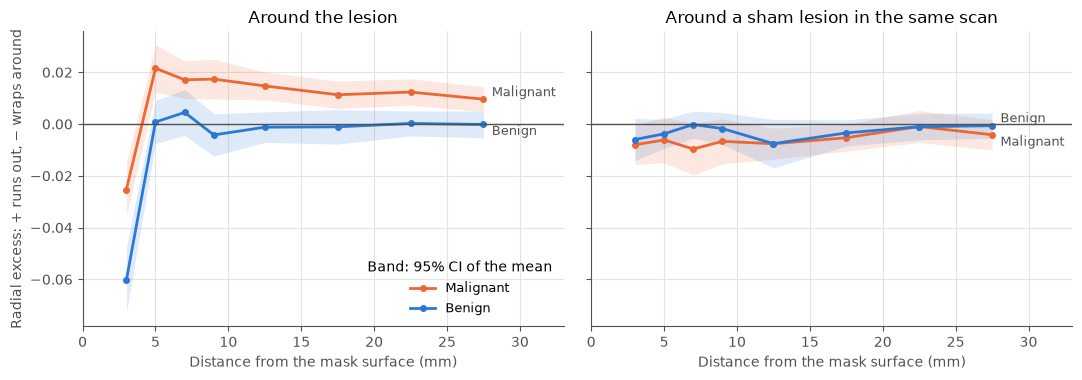

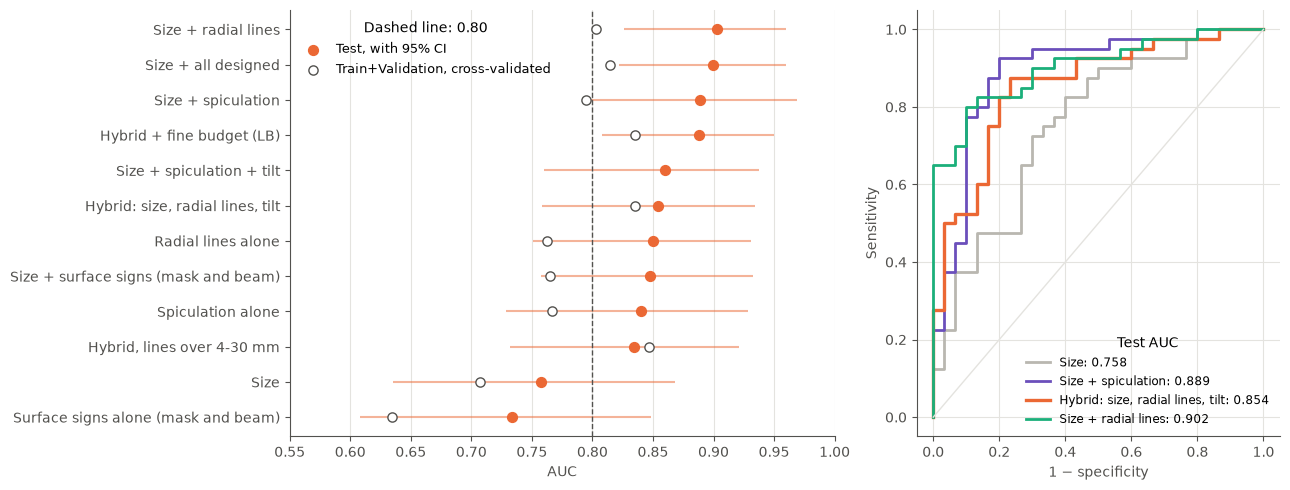

In [15]:
plot_reach(test_shells, A + "reach-test.png")
from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw=dict(width_ratios=[1.5, 1]))
order = test_results.sort_values("AUC").index; ax = axes[0]; cv = models.auc.reindex(order); cv["Hybrid, lines over 4-30 mm"] = pd.read_csv(O + "reach.csv", index_col=0).loc["4-30 mm", "hybrid_auc"]
ax.hlines(order, test_results.AUC_low[order], test_results.AUC_high[order], color=ORANGE, lw=1.5, alpha=.5); ax.scatter(test_results.AUC[order], order, color=ORANGE, s=50, zorder=3, label="Test, with 95% CI"); ax.scatter(cv[order], order, facecolors="white", edgecolors=INK, s=44, zorder=4, label="Train+Validation, cross-validated")
ax.axvline(.8, color=INK, lw=1, ls="--"); ax.set(xlabel="AUC", xlim=(.55, 1)); ax.grid(axis="y", visible=False); ax.legend(frameon=False, fontsize=9, loc="upper left", title="Dashed line: 0.80")
ax = axes[1]
for name, colour, lw in (("Size", MUTED, 2), ("Size + spiculation", PURPLE, 2), (plan["primary"], ORANGE, 2.4), ("Size + radial lines", AQUA, 2)):
    fpr, tpr, _ = roc_curve(y_test, test_preds[name]); ax.plot(fpr, tpr, color=colour, lw=lw, label=f"{name}: {test_results.AUC[name]:.3f}")
ax.plot([0, 1], [0, 1], color=GRID, lw=1); ax.set(xlabel="1 − specificity", ylabel="Sensitivity"); ax.legend(frameon=False, fontsize=8.5, loc="lower right", title="Test AUC")
fig.tight_layout(); fig.savefig(A + "test.png", dpi=150, bbox_inches="tight"); plt.show()

The malignant line is close to the Train+Validation one in Section 6: 0.022 at 4–6 mm falling to 0.010 at 25–30 mm, with benign lesions near zero. Sham lesions do not separate the classes (AUC 0.43, 95% CI 0.29–0.58).

**Models against their Train+Validation estimates.** The left panel of the figure above shows Test AUC beside the cross-validated one. No cross-validated estimate was computed for size + spiculation + tilt. Most models score higher on Test, including size alone (0.758 against 0.707), so this split looks easier, or the larger training set helps. Scores from the two cannot be compared directly.

- **Both targets are passed, and size + spiculation stays ahead.** The hybrid reaches AUC 0.854 (0.758–0.934) and ACC 0.814. Size + spiculation reaches 0.889 and 0.871, the same as in the earlier evaluation. The hybrid's +0.038 on Train+Validation became −0.035.
- **Tilt did not replicate.** AUC is 0.488 raw (0.343–0.633) and 0.607 after volume (0.461–0.743), against 0.599 and 0.680 on Train+Validation. Tan's height-to-width ratio held up better, at 0.636 raw and 0.670 after volume.
- **Tissue lines did.** After volume they tie with SP90, 0.767 against 0.756, and they stay independent of size (Spearman −0.04 against 0.26). Within a lesion, bumps still do not sit where lines run out (median Spearman 0.03 and 0.07).
- **The wider shell did not help:** −0.020 (−0.057 to 0.016). It was a Train+Validation lead that we did not adopt.
- **The surface did better here than on Train+Validation.** Surface signs alone reach AUC 0.733 (0.608–0.849). The fine area budget alone reaches 0.758 after volume (0.625–0.873). That is the first LB measure in this project with signal beyond volume on held-out data, though it is one of eight single features checked. Whether it adds to size + spiculation was not in the plan, and testing it now would be a third look at Test.

**Outside the plan.** The next cell was written after the results were seen, and uses only models already frozen, with nothing refitted. Treat it as description, not as evidence for picking a model.

In [16]:
from abus_classification.lb_classification import delta
from abus_classification.lb_malignancy import decision, descriptor_columns
pairs = [("Size + spiculation", "Size + radial lines"), (plan["primary"], "Size + radial lines"), ("Size", "Size + radial lines"), ("Size", "Size + surface signs (mask and beam)"), ("Size + radial lines", "Size + all designed"), ("Spiculation alone", "Radial lines alone")]
display(pd.DataFrame({f"{a} → {b}": delta(test_preds[a].values, test_preds[b].values, y_test) for a, b in pairs}).T[["before", "after", "gain", "low", "high"]].round(3))
p = np.load(O + "predicted.npz"); columns = descriptor_columns(p); renders = p["volume"].shape[1]
frames = [pd.DataFrame({"Size: log volume": np.log(p["volume"][:, r]), "Size: log area": np.log(p["area"][:, r]), **{k: v[:, r] for k, v in columns.items()}}) for r in range(renders)]
table_masks = {}
for name in (plan["primary"], "Size", "Size + radial lines", "Radial lines alone", "Size + surface signs (mask and beam)", "Surface signs alone (mask and beam)", "Hybrid + fine budget (LB)"):
    found = []
    for frame in frames:
        s = decision(plan["models"][name], frame); miss = ~np.isfinite(s); s[miss] = np.nanmin(s) - 1; found.append((roc_auc_score(y_test, s), ((s >= 0) == y_test).mean()))
    found = np.array(found); table_masks[name] = {"In the plan": name in plan["predicted_masks"]["models"], "True, AUC": found[0, 0], "True, ACC": found[0, 1], "Predicted, AUC": found[1:, 0].mean(), "AUC low seed": found[1:, 0].min(), "AUC high seed": found[1:, 0].max(), "Predicted, ACC": found[1:, 1].mean(), "ACC low seed": found[1:, 1].min(), "ACC high seed": found[1:, 1].max()}
display(pd.DataFrame(table_masks).T.infer_objects().round(3)); print("Misses of 70, by seed:", test_predicted[test_predicted.model == plan["primary"]].misses.tolist()[1:])
from abus_classification import challenge
mean = table_masks[plan["primary"]]; print("Hybrid on predicted masks, as if entered alone on the classification board:", challenge.benchmark({"Hybrid": {"ACC": mean["Predicted, ACC"], "AUC": mean["Predicted, AUC"]}})["Cls_Rank"].iloc[0])

,before,after,gain,low,high
Size + spiculation → Size + radial lines,0.889,0.903,0.013,-0.042,0.078
"Hybrid: size, radial lines, tilt → Size + radial lines",0.854,0.903,0.048,0.005,0.101
Size → Size + radial lines,0.758,0.903,0.145,0.042,0.258
Size → Size + surface signs (mask and beam),0.758,0.848,0.090,-0.028,0.213
Size + radial lines → Size + all designed,0.903,0.899,-0.003,-0.059,0.048
Spiculation alone → Radial lines alone,0.840,0.850,0.010,-0.084,0.101


,In the plan,"True, AUC","True, ACC","Predicted, AUC",AUC low seed,AUC high seed,"Predicted, ACC",ACC low seed,ACC high seed
"Hybrid: size, radial lines, tilt",True,0.869,0.771,0.820,0.792,0.838,0.781,0.771,0.786
Size,True,0.759,0.700,0.697,0.688,0.704,0.662,0.657,0.671
Size + radial lines,False,0.892,0.800,0.835,0.822,0.851,0.781,0.743,0.800
Radial lines alone,False,0.827,0.743,0.771,0.758,0.783,0.652,0.629,0.671
Size + surface signs (mask and beam),False,0.854,0.743,0.720,0.699,0.731,0.586,0.529,0.614
Surface signs alone (mask and beam),False,0.786,0.700,0.640,0.588,0.678,0.433,0.429,0.443
Hybrid + fine budget (LB),False,0.903,0.786,0.812,0.796,0.836,0.595,0.571,0.614


Misses of 70, by seed: [1, 1, 2]
Hybrid on predicted masks, as if entered alone on the classification board: 2/9


**Between models.**
- **Size + radial lines has the highest AUC of the 12,** 0.902 (0.826–0.959), with ACC 0.786. Being the best of 12, it is not a result. Against size + spiculation it ties: 0.013 (−0.042 to 0.078).
- **Dropping tilt from the hybrid raises AUC by 0.048** (0.005 to 0.101), which agrees with tilt failing.
- **Lines add 0.145 to size** (0.042 to 0.258). Surface signs add 0.090 (−0.028 to 0.213), and nothing once lines are in (−0.003).

**On real segmentations.** Zhou 2021's masks, three seeds, on patches centred on the true lesion; a miss scores lowest.
- **In the plan:** the hybrid keeps AUC 0.820 (0.792–0.838 across seeds) and ACC 0.781 (0.771–0.786), while size falls to 0.697 and 0.662. Zhou's own classification head scores AUC 0.67 and ACC 62.9% on the same lesions.
- **Outside the plan:** surface signs alone fall to AUC 0.640 and ACC 0.433, below the 0.571 of always answering malignant. Predicted surfaces are much smoother (median fine area budget about a quarter of the true masks'), so that model calls almost every lesion benign. This confirms what the ranks in Section 8 suggested.
- **Not run:** spiculation on predicted masks. Tan's map does not depend on the mask, only its summary does, so it may hold up as well.
- **A full pipeline has a harder job,** since it must also find the lesion.

## 10. What a 3D surface can and cannot show

1. **Malignancy cannot be read from a surface.** It is defined by histology, and some cancers look benign while some benign lesions look malignant [6–8].
2. **The mask's own shape carries a modest signal that does not survive real segmentation:** AUC 0.63 on Train+Validation, 0.73 on Test, then 0.64 and ACC 0.43 on predicted masks.
3. **The surface is most useful as a reference,** the place from which to read the tissue around the lesion. Its tilt against the skin did not hold up.
4. **What separates the classes most reliably lies outside the surface,** in tissue lines converging on the lesion from as far as 30 mm. It replicated on Test and survives predicted masks.

| Sign | Train+Validation, AUC after volume | Test, AUC after volume | True vs predicted masks, rank |
|---|---|---|---|
| Tissue lines converging, spicules | 0.74 | 0.77, reach replicated | 0.80–0.84 |
| Tan's spiculation, SP90 | 0.71 | 0.76 | Not run |
| Not parallel to the skin, tilt | 0.68 | 0.61, raw 0.49: **failed** | 0.43 |
| Tan's height-to-width ratio | 0.67 | 0.67 | Not run |
| Irregular, fine area budget | 0.66 | 0.76 | 0.16 |

## 11. Protocol

- **Data:** TDSC-ABUS. Sections 1–8 use Train+Validation, 130 lesions (75 malignant), for every class result. Section 9 uses Test, 70 lesions (40 malignant). True masks, except where predicted masks are named. Malignant is the positive class.
- **Evaluation:** logistic regression on standardised features, 20 repeats of five-fold CV; random forest with 300 trees, 5 repeats; bootstrap over lesions on mean out-of-fold scores or Test scores. There is no network training here, so no seeds. Predicted masks come from Zhou 2021's 3 stored seeds.
- **Rerun:** see [`docs/reproductions/lb-malignancy.md`](../docs/reproductions/lb-malignancy.md). CPU only, no Kaggle kernel. Rerunning reproduces the numbers; it does not make Test unseen.
- **Results:** `results/lb-malignancy/`.

## 12. Open issues

- **Test has now been used twice.** Size + radial lines looks like the next candidate, but it was the best of 12 on this split, and it cannot be validated here. That needs new data, such as IIPL-3D-ABUS.
- **The fine area budget on size + spiculation** is untested on held-out data, and it fails on predicted masks.
- **A full pipeline.** Predicted-mask results use patches centred on the true lesion. Spiculation was not run on predicted masks.
- **What the lines are.** Ligaments, ducts, fibrosis or strands of tumour: nothing here separates them. The link to collagen [4, 5] is an analogy across very different scales, not a finding.
- **What the masks leave out.** Whether real spicules could be annotated, and how much surface roughness comes from slice-by-slice drawing, needs repeat or finer annotations.
- **Why tilt failed.** It may be noise on Train+Validation, or ABUS compression, which flattens lesions. It is also poorly defined on near-round lesions. Height-to-width held up better.
- **Size.** We do not know how much of its signal comes from which lesions reached this dataset.
- **Scale.** Lobes are measured relative to the lesion's radius, while microlobulation is defined in millimetres. A fixed-millimetre version is untested.
- **Not fused yet:** intensity and CNN features, as the roadmap step also asks.

## References

1. D. Hanahan, R. A. Weinberg. Hallmarks of cancer: the next generation. *Cell* 144:646–674, 2011. [doi](https://doi.org/10.1016/j.cell.2011.02.013)
2. A. T. Stavros et al. Solid breast nodules: use of sonography to distinguish between benign and malignant lesions. *Radiology* 196:123–134, 1995. [doi](https://doi.org/10.1148/radiology.196.1.7784555)
3. V. Cristini et al. Morphologic instability and cancer invasion. *Clin Cancer Res* 11:6772–6779, 2005. [doi](https://doi.org/10.1158/1078-0432.CCR-05-0852)
4. P. P. Provenzano et al. Collagen reorganization at the tumor-stromal interface facilitates local invasion. *BMC Medicine* 4:38, 2006. [doi](https://doi.org/10.1186/1741-7015-4-38)
5. M. W. Conklin et al. Aligned collagen is a prognostic signature for survival in human breast carcinoma. *Am J Pathol* 178:1221–1232, 2011. [doi](https://doi.org/10.1016/j.ajpath.2010.11.076)
6. T. Franquet et al. Spiculated lesions of the breast: mammographic-pathologic correlation. *RadioGraphics* 13:841–852, 1993. [doi](https://doi.org/10.1148/radiographics.13.4.8356272)
7. E. S. Ko et al. Triple-negative breast cancer: correlation between imaging and pathological findings. *Eur Radiol* 20:1111–1117, 2010. [doi](https://doi.org/10.1007/s00330-009-1656-3)
8. B. E. Dogan, L. W. Turnbull. Imaging of triple-negative breast cancer. *Ann Oncol* 23:vi23–vi29, 2012. [doi](https://doi.org/10.1093/annonc/mds191)
9. A. S. Hong et al. BI-RADS for sonography: positive and negative predictive values of sonographic features. *AJR* 184:1260–1265, 2005. [doi](https://doi.org/10.2214/ajr.184.4.01841260)
10. F. Y. Zheng et al. Comparison of retraction phenomenon and BI-RADS-US descriptors in differentiating benign and malignant breast masses using an automated breast volume scanner. *Eur J Radiol* 84:2123–2129, 2015. [doi](https://doi.org/10.1016/j.ejrad.2015.07.028)
11. M. Meyer et al. Discrete differential-geometry operators for triangulated 2-manifolds. *Visualization and Mathematics III*, 35–57, 2003. [doi](https://doi.org/10.1007/978-3-662-05105-4_2)
12. F. C. Marques, A. Neves. Min-max theory and the Willmore conjecture. *Ann of Math* 179:683–782, 2014, which sets out the background. [doi](https://doi.org/10.4007/annals.2014.179.2.6)
13. T. Takahashi. Minimal immersions of Riemannian manifolds. *J Math Soc Japan* 18:380–385, 1966. [doi](https://doi.org/10.2969/jmsj/01840380)
14. R. C. Reilly. On the first eigenvalue of the Laplacian for compact submanifolds of Euclidean space. *Comment Math Helv* 52:525–533, 1977. [doi](https://doi.org/10.1007/BF02567385)
15. D. Cohen-Steiner, H. Edelsbrunner, J. Harer. Stability of persistence diagrams. *Discrete Comput Geom* 37:103–120, 2007. [doi](https://doi.org/10.1007/s00454-006-1276-5)
16. T. Tan et al. Computer-aided lesion diagnosis in automated 3-D breast ultrasound using coronal spiculation. *IEEE TMI* 31:1034–1042, 2012. [doi](https://doi.org/10.1109/TMI.2012.2184549)